# Multiple groups with MGPPM

Estimate how trait scores differ between two groups who answered the same
forced-choice blocks. Both groups use the same statement parameters, so their
population means are comparable on a common trait scale.

## Model group differences on a shared scale

Let $g(p)\in\{A,B\}$ be person $p$'s group. The person's vector of trait
scores has a group-specific multivariate normal distribution:

$$
\boldsymbol\theta_p\mid g(p)=g
\sim\mathcal N(\boldsymbol\mu_g,\mathbf R_g),\qquad
\boldsymbol\mu_A=\mathbf 0,\qquad
\operatorname{diag}(\mathbf R_g)=\mathbf 1.
$$

Each component $\mu_{B,t}$ of $\boldsymbol\mu_B$ is the mean difference
between B and A on trait $t$. Both groups have SD one on each trait.
The correlation matrix $\mathbf R_g$ can differ between groups.

The [MGPPM ranking law](mgppm_workflow.ipynb#model-the-ranking-patterns)
uses the same utility parameters in both groups. For statement $j$,
the utility is $u_{pj}=q_j a_j\theta_{p,t(j)}-b_j$: keying $q_j$ sets
the direction, $a_j$ is the loading magnitude and $b_j$ is the intercept.
An order $j>k>\ell$ of three statements has weight $\exp(2u_{pj}+u_{pk})$.
Divide it by the total weight of all six orders to get the probability. Sharing the statement parameters puts the estimated
group differences on a common measurement scale.

## Load rankings and group labels

The bundled simulation contains complete rankings from 60 respondents in each
group, across 12 triplets. Group B's generating mean is 0.60 higher on
`theta1`. The groups have the same generating means on the other three traits.

In [1]:
import seaborn as sns

import pyfcirt as fc

sns.set_theme(style="ticks")

example = fc.load_example("mgppm_groups", model="MGPPM", include_truth=True)
design = example.data.design
responses = example.data.responses.frame
people = example.person_data

design.head(3)

,block_id,position,statement_id,trait,keying
0,B1,1,S1,theta1,1
1,B1,2,S2,theta2,1
2,B1,3,S3,theta3,1


The group table contains one row per respondent. PyFCIRT matches the
`group` column to responses by `person_id`.

In [2]:
people.groupby("group").head(2)

,person_id,group
0,1,A
1,2,A
60,61,B
61,62,B


## Set the reference group

Use `PopulationSpec` to read group membership from the `group` column
and fix group A's trait means at zero.

In [3]:
population = fc.PopulationSpec(group="group", reference_group="A")
model = fc.Model()
model.add_fc(
    design,
    responses,
    format="block_long",
    model="MGPPM",
    response_format="rank",
)
model.prepare(
    population=population,
    person_data=people,
    theta_parameterization="noncentered",
);

## Fit the grouped model

In [4]:
model.fit(draws=2000, tune=3500, chains=4, random_seed=45);

## Diagnose the chains

The maximum R-hat is 1.007. The minimum bulk and tail effective sample sizes
are 1,046 and 954, with zero divergences.

In [5]:
import arviz as az
import numpy as np

posterior = model.idata.posterior.to_dataset().reset_coords(drop=True)
with np.errstate(invalid="ignore", divide="ignore"):
    r_hat = az.rhat(posterior).max().to_array().max().item()
    bulk = az.ess(posterior, method="bulk").min().to_array().min().item()
    tail = az.ess(posterior, method="tail").min().to_array().min().item()

print(f"Max R-hat: {r_hat:.3f}")
print(f"Min bulk / tail ESS: {bulk:.0f} / {tail:.0f}")
print("Divergences:", int(model.idata.sample_stats.diverging.sum()))

Max R-hat: 1.007
Min bulk / tail ESS: 1046 / 954
Divergences: 0


The two panels check the chains for group B's mean on theta1. This is the
same group difference interpreted below. Its rank-test p-value is about 0.02.

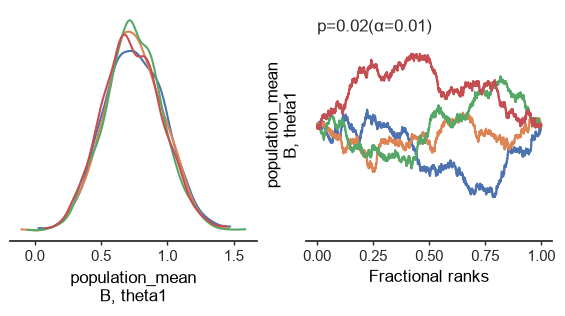

In [6]:
import arviz_plots as azp
import matplotlib.pyplot as plt

azp.plot_rank_dist(
    model.idata,
    var_names=["population_mean"],
    coords={"population_group": ["B"], "trait": ["theta1"]},
    backend="matplotlib",
    compact=False,
    figure_kwargs={"figsize": (7, 3)},
)
plt.show()

## Read the shared loadings

Each B1 statement has one estimated loading. The same value applies to
respondents in both groups.

In [7]:
loadings = model.coef(blocks=["B1"], var_names="loading", kind="stats")
loadings.round(2)

mean    sd  hdi95_lb  hdi95_ub
unit statement trait  parameter                                
B1   S1        theta1 loading    0.59  0.15      0.31      0.90
     S2        theta2 loading    0.64  0.16      0.35      0.97
     S3        theta3 loading    0.75  0.18      0.40      1.11

## Compare correlations and individual scores

The heatmaps show the estimated correlations between traits in each group.
The density panels show how individual scores vary. Each respondent contributes
one posterior mean score per trait.

In [8]:
correlations = model.idata.posterior.trait_correlation.mean(("chain", "draw"))

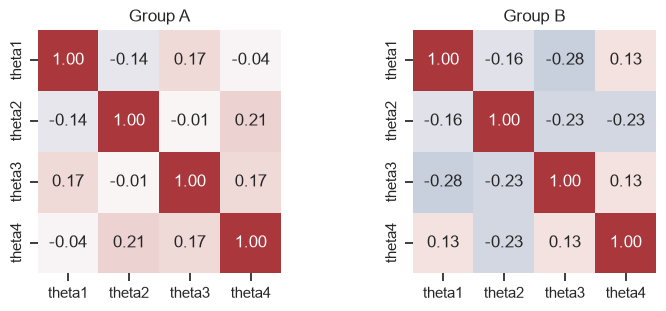

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3), layout="constrained")
for ax, group in zip(axes, ["A", "B"], strict=True):
    matrix = correlations.sel(population_group=group).to_pandas()
    sns.heatmap(
        matrix,
        vmin=-1,
        vmax=1,
        center=0,
        cmap="vlag",
        annot=True,
        fmt=".2f",
        square=True,
        cbar=False,
        ax=ax,
    )
    ax.set(title=f"Group {group}", xlabel="", ylabel="")
plt.show()

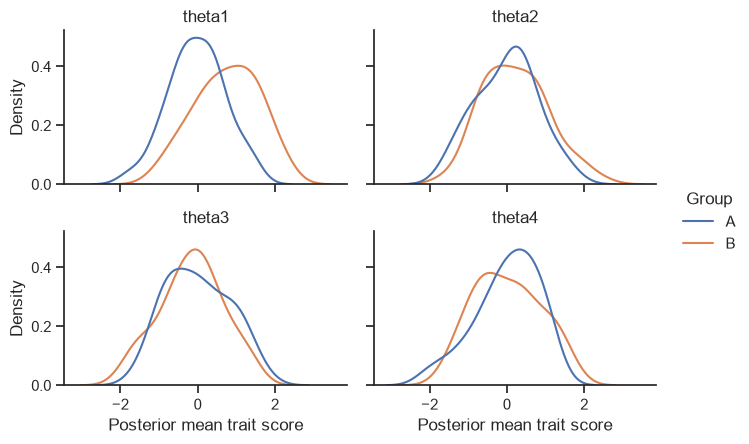

In [10]:
scores = model.idata.posterior.theta.mean(("chain", "draw"))
score_table = scores.to_series().rename("Score").reset_index()
groups = people.set_index("person_id").group
score_table["Group"] = score_table.person.map(groups)
chart = sns.displot(
    data=score_table,
    x="Score",
    hue="Group",
    col="trait",
    col_wrap=2,
    kind="kde",
    common_norm=False,
    height=2.3,
    aspect=1.5,
)
chart.set_axis_labels("Posterior mean trait score", "Density")
chart.set_titles("{col_name}")
plt.show()

## Compare group means

The density shows the posterior for group B's mean on `theta1`.
The forest plot shows the posterior mean and 95% highest density interval for
each trait. Gray diamonds mark the generating values. Group A has mean zero
on the reference scale, so each plotted mean is also the difference B − A.

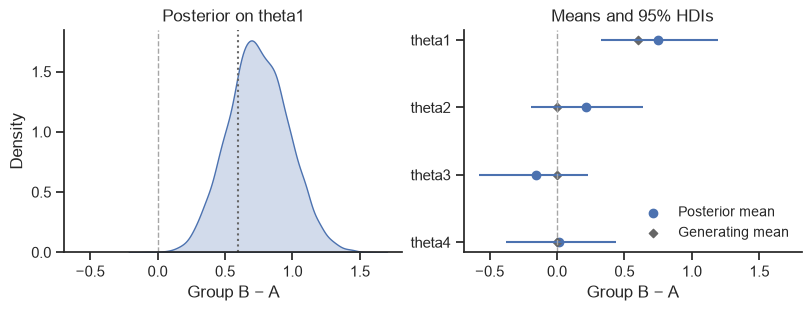

In [11]:
posterior = model.idata.posterior.population_mean.sel(population_group="B")
truth = example.truth.population_mean.sel(population_group="B")
center = posterior.mean(("chain", "draw"))
interval = az.hdi(posterior, prob=0.95)
traits = posterior.trait.values

fig, (dist, forest) = plt.subplots(1, 2, figsize=(8, 3), sharex=True, layout="constrained")
sns.kdeplot(x=posterior.sel(trait="theta1").values.ravel(), fill=True, ax=dist)
dist.axvline(truth.sel(trait="theta1").item(), color="0.4", linestyle=":")
dist.set(title="Posterior on theta1", xlabel="Group B − A", ylabel="Density")

forest.hlines(
    traits,
    interval.sel(ci_bound="lower"),
    interval.sel(ci_bound="upper"),
    color="C0",
)
forest.scatter(center, traits, color="C0", label="Posterior mean")
forest.scatter(truth, traits, color="0.4", marker="D", s=18, label="Generating mean")
forest.invert_yaxis()
forest.set(title="Means and 95% HDIs", xlabel="Group B − A")
forest.legend(frameon=False, fontsize="small")

for ax in (dist, forest):
    ax.axvline(0, color="0.65", linestyle="--", linewidth=1)
sns.despine()
plt.show()

For `theta1`, the estimated difference is 0.75 (95% HDI [0.33, 1.19]). The intervals for the other three traits include zero.